# R03 · Main experiments: detection and uncertainty against **errors**, 5 seeds

Uncertainty is evaluated both against the anomaly labels and against the **errors** of the detector, to see
whether it identifies unreliable predictions. Each model is trained with 5 seeds (0–4). Each B3 run also gives M3 (conformal on **the same** B3 scores, no
retraining). Each deterministic LSTM run gives M4.

### How to read the uncertainty columns
* **label-AUROC**: does uncertainty separate anomalies from normal windows?
* **error-AUROC**: does uncertainty separate **wrong** decisions from **right** ones? 0.5 = useless.
* **AURC**: average error rate when you keep only the most confident windows, over all coverage levels.
  Lower is better. Compare with **random** (reject at random) and **oracle** (reject exactly the errors).
* **margin**: a free baseline every detector already has: how close the score is to the threshold.
  An uncertainty method is only useful if it beats this.
* **vote**: MCD decision disagreement: share of the 50 dropout passes that flag the window, f·(1−f).

In [1]:
# ── Settings ──────────────────────────────────────────────────────────────
import os
WORKERS = int(os.environ.get("REV_WORKERS", 8))   # training jobs side by side on the GPU
DEVICE  = None     # None = use the GPU if there is one
RESULTS = os.environ.get("REV_RESULTS", "results")
RUN     = os.environ.get("REV_RUN", "1") == "1"   # False = skip training, rebuild tables/figures from results/

import warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src import report, plots
from scripts.run_jobs import run_stage, stage_tags
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
os.makedirs("tables_rev", exist_ok=True)

def export(df, name):
    """Save a table as tables_rev/REV_<name>.csv and show it."""
    path = f"tables_rev/REV_{name}.csv"; df.to_csv(path); display(df); print("saved", path)

In [2]:
if RUN:
    failed = run_stage("main", workers=WORKERS, device=DEVICE, results=RESULTS)

In [3]:
df = report.load(RESULTS)
V = report.views(df)
print(len(df), "records")

250 records


## Table A · Detection performance (mean ± std over seeds)

In [4]:
MAIN = ["B1 Z-score","B2 IsoForest","B3 Dense AE","M1 Dense+MCD","M2 LSTM+MCD",
        "LSTM AE (det.)","M3 Dense+CP","M4 LSTM+CP"]
V = V[V.tag.isin(stage_tags("main"))]          # only the runs of this stage
Vm = V[V.method.isin(MAIN)]
ta = report.mean_std(Vm, ["auc_pr","auroc","f1","precision","recall"])
ta["AUC-PR chance"] = Vm.groupby(["dataset","method"])["auc_pr_chance"].first().round(3)
export(ta, "tableA_detection")

auc_pr          auroc             f1      precision         recall  n_seeds  AUC-PR chance
dataset method                                                                                                           
NAB     B1 Z-score              0.148          0.526          0.105          0.162          0.078        1          0.119
        B2 IsoForest    0.165 ± 0.001  0.597 ± 0.001  0.121 ± 0.003  0.174 ± 0.004  0.093 ± 0.002        5          0.119
        B3 Dense AE     0.229 ± 0.000  0.644 ± 0.001  0.294 ± 0.000  0.316 ± 0.001  0.275 ± 0.001        5          0.119
        LSTM AE (det.)  0.224 ± 0.002  0.643 ± 0.002  0.291 ± 0.005  0.310 ± 0.011  0.274 ± 0.003        5          0.119
        M1 Dense+MCD    0.229 ± 0.001  0.645 ± 0.001  0.295 ± 0.001  0.309 ± 0.002  0.283 ± 0.001        5          0.119
        M2 LSTM+MCD     0.224 ± 0.002  0.641 ± 0.002  0.294 ± 0.004  0.314 ± 0.011  0.277 ± 0.006        5          0.119
        M3 Dense+CP     0.229 ± 0.000  0.644 ± 0.001  0.285 ± 0.002  0.355 ± 0.001  0.238 ± 0.002        5          0.119
        M4 LSTM+CP      0.224 ± 0.002  0.643 ± 0.002  0.286 ± 0.005  0.322 ± 0.013  0.258 ± 0.004        5          0.119
SKAB    B1 Z-score              0.846          0.779          0.794          0.718          0.888        1          0.608
        B2 IsoForest    0.798 ± 0.027  0.734 ± 0.034  0.722 ± 0.035  0.751 ± 0.018  0.696 ± 0.051        5          0.608
        B3 Dense AE     0.855 ± 0.001  0.801 ± 0.001  0.817 ± 0.002  0.754 ± 0.001  0.890 ± 0.004        5          0.608
        LSTM AE (det.)  0.851 ± 0.002  0.796 ± 0.002  0.816 ± 0.001  0.749 ± 0.003  0.896 ± 0.004        5          0.608
        M1 Dense+MCD    0.854 ± 0.002  0.799 ± 0.003  0.815 ± 0.002  0.756 ± 0.006  0.885 ± 0.004        5          0.608
        M2 LSTM+MCD     0.850 ± 0.001  0.792 ± 0.002  0.814 ± 0.003  0.750 ± 0.004  0.890 ± 0.005        5          0.608
        M3 Dense+CP     0.855 ± 0.001  0.801 ± 0.001  0.784 ± 0.003  0.795 ± 0.003  0.774 ± 0.005        5          0.608
        M4 LSTM+CP      0.851 ± 0.002  0.796 ± 0.002  0.786 ± 0.002  0.784 ± 0.004  0.789 ± 0.005        5          0.608

saved tables_rev/REV_tableA_detection.csv


## Table B · Uncertainty quality: label-AUROC vs error-AUROC

In [5]:
U = V[V.method.isin(["M1 Dense+MCD","M2 LSTM+MCD"])]
cols = [c for c in ["std/label_auroc","std/error_auroc","vote/error_auroc","cv/error_auroc",
                    "margin/error_auroc"] if c in U]
export(report.mean_std(U, cols), "tableB_uncertainty_auroc")

std/label_auroc std/error_auroc vote/error_auroc cv/error_auroc margin/error_auroc  n_seeds
dataset method                                                                                                  
NAB     M1 Dense+MCD   0.626 ± 0.014   0.706 ± 0.012    0.537 ± 0.006  0.329 ± 0.009      0.645 ± 0.002        5
        M2 LSTM+MCD    0.623 ± 0.011   0.698 ± 0.005    0.521 ± 0.004  0.390 ± 0.013      0.650 ± 0.008        5
SKAB    M1 Dense+MCD   0.810 ± 0.007   0.400 ± 0.007    0.537 ± 0.002  0.542 ± 0.021      0.646 ± 0.002        5
        M2 LSTM+MCD    0.760 ± 0.019   0.430 ± 0.015    0.523 ± 0.009  0.595 ± 0.031      0.637 ± 0.007        5

saved tables_rev/REV_tableB_uncertainty_auroc.csv


## Table C · Selective prediction: AURC (lower = better)

In [6]:
cols = ["std/aurc","vote/aurc","margin/aurc","random/aurc","oracle/aurc"]
export(report.mean_std(U, cols, digits=4), "tableC_aurc")

std/aurc        vote/aurc      margin/aurc      random/aurc      oracle/aurc  n_seeds
dataset method                                                                                                    
NAB     M1 Dense+MCD  0.0961 ± 0.0085  0.1916 ± 0.0026  0.1113 ± 0.0009  0.1611 ± 0.0009  0.0138 ± 0.0001        5
        M2 LSTM+MCD   0.0907 ± 0.0023  0.1933 ± 0.0075  0.1059 ± 0.0012  0.1586 ± 0.0037  0.0134 ± 0.0008        5
SKAB    M1 Dense+MCD  0.2656 ± 0.0018  0.1735 ± 0.0060  0.1532 ± 0.0023  0.2462 ± 0.0037  0.0325 ± 0.0012        5
        M2 LSTM+MCD   0.2676 ± 0.0058  0.1811 ± 0.0048  0.1589 ± 0.0012  0.2493 ± 0.0069  0.0336 ± 0.0011        5

saved tables_rev/REV_tableC_aurc.csv


## Table D · Conformal prediction: false-alarm rate on **normal** test windows (target α = 0.05)

In [7]:
CPM = ["M3 Dense+CP","M4 LSTM+CP","M1 Dense+MCD + CP","M2 LSTM+MCD + CP"]
C_ = V[V.method.isin(CPM)]
export(report.mean_std(C_, ["fpr@0.01","fpr@0.05","fpr@0.1","coverage@0.05","n_cal"]), "tableD_conformal")

fpr@0.01       fpr@0.05        fpr@0.1  coverage@0.05              n_cal  n_seeds
dataset method                                                                                                   
NAB     M1 Dense+MCD + CP  0.034 ± 0.001  0.064 ± 0.001  0.119 ± 0.002  0.936 ± 0.001  29753.000 ± 0.000        5
        M2 LSTM+MCD + CP   0.032 ± 0.000  0.072 ± 0.005  0.135 ± 0.014  0.928 ± 0.005  29753.000 ± 0.000        5
        M3 Dense+CP        0.035 ± 0.001  0.059 ± 0.001  0.113 ± 0.001  0.941 ± 0.001  29753.000 ± 0.000        5
        M4 LSTM+CP         0.032 ± 0.001  0.074 ± 0.005  0.133 ± 0.007  0.926 ± 0.005  29753.000 ± 0.000        5
SKAB    M1 Dense+MCD + CP  0.050 ± 0.001  0.319 ± 0.005  0.494 ± 0.003  0.681 ± 0.005   1854.000 ± 0.000        5
        M2 LSTM+MCD + CP   0.053 ± 0.009  0.346 ± 0.011  0.502 ± 0.010  0.654 ± 0.011   1854.000 ± 0.000        5
        M3 Dense+CP        0.050 ± 0.002  0.310 ± 0.006  0.480 ± 0.004  0.690 ± 0.006   1854.000 ± 0.000        5
        M4 LSTM+CP         0.045 ± 0.010  0.336 ± 0.010  0.487 ± 0.015  0.664 ± 0.010   1854.000 ± 0.000        5

saved tables_rev/REV_tableD_conformal.csv


## Figures

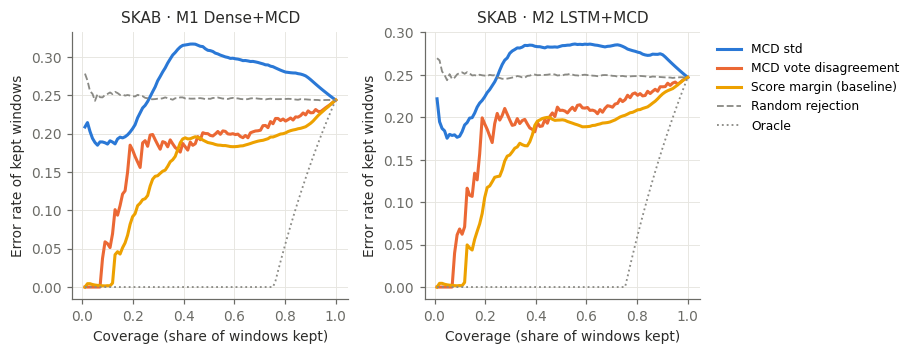

saved figures_rev/REV_risk_coverage_SKAB.png


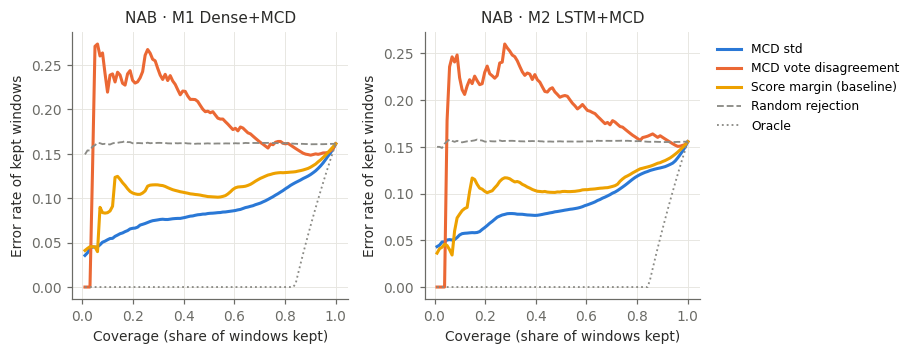

saved figures_rev/REV_risk_coverage_NAB.png


In [8]:
def first_tag(method, ds, seed=0):
    t = V[(V.method == method) & (V.dataset == ds) & (V.seed == seed)]
    return t.iloc[0]["tag"]
for ds in ("SKAB", "NAB"):
    items = [(f"{ds} · M1 Dense+MCD", first_tag("M1 Dense+MCD", ds), "mc_val", ["std","vote","margin"]),
             (f"{ds} · M2 LSTM+MCD",  first_tag("M2 LSTM+MCD", ds),  "mc_val", ["std","vote","margin"])]
    fig, path = plots.risk_coverage(RESULTS, items, f"REV_risk_coverage_{ds}"); plt.show(); print("saved", path)

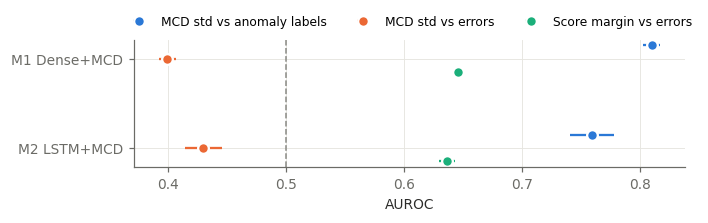

saved figures_rev/REV_label_vs_error_auroc_SKAB.png


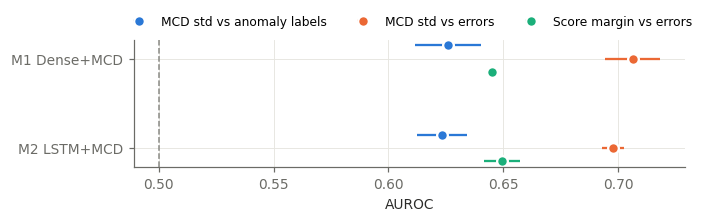

saved figures_rev/REV_label_vs_error_auroc_NAB.png


In [9]:
for ds in ("SKAB", "NAB"):
    t = U[U.dataset == ds].groupby("method")[["std/label_auroc","std/error_auroc","margin/error_auroc"]].agg(["mean","std"])
    t.columns = [f"{a}_{b}" for a, b in t.columns]; t = t.reset_index()
    fig, path = plots.dot_compare(t, ["std/label_auroc","std/error_auroc","margin/error_auroc"],
                                  ["MCD std vs anomaly labels","MCD std vs errors",
                                   "Score margin vs errors"],
                                  f"REV_label_vs_error_auroc_{ds}")
    plt.show(); print("saved", path)

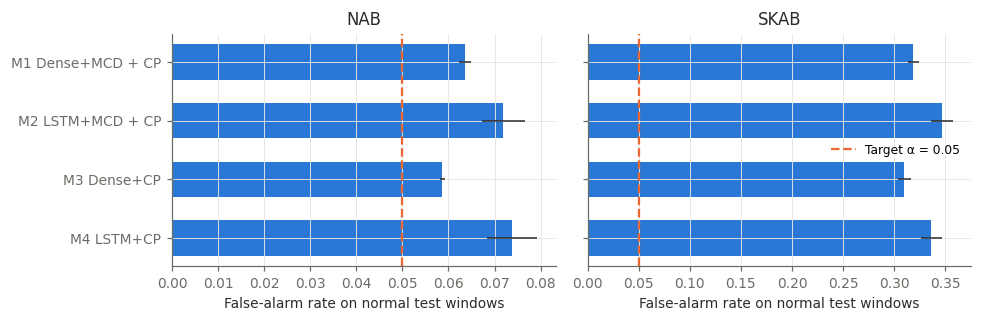

saved figures_rev/REV_conformal_false_alarm_rate.png


In [10]:
t = C_.groupby(["dataset","method"])["fpr@0.05"].agg(["mean","std"]).reset_index()
t.columns = ["dataset","method","fpr_mean","fpr_std"]
fig, path = plots.conformal_fpr(t); plt.show(); print("saved", path)